In [1]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images


In [2]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [3]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


# EfficientNet B3 with Adaboost


########## SEED = 512 ##########



100%|██████████| 43/43 [00:34<00:00,  1.26it/s]


Epoch [1/50] Train Loss: 0.4373 (CE: 0.5317, Dice: 0.3428), Train Acc: 0.6963 | Val Loss: 0.4587 (CE: 0.5588, Dice: 0.3585), Val Acc: 0.7042
  -> Saving best model (Val Accuracy: 0.7042)


100%|██████████| 43/43 [00:34<00:00,  1.23it/s]


Epoch [2/50] Train Loss: 0.4181 (CE: 0.5091, Dice: 0.3271), Train Acc: 0.7129 | Val Loss: 0.4700 (CE: 0.5802, Dice: 0.3597), Val Acc: 0.6667
  -> No improvement for 1/8 epochs


...

Epoch [13/50] Train Loss: 0.3569 (CE: 0.4306, Dice: 0.2832), Train Acc: 0.7585 | Val Loss: 0.4431 (CE: 0.5414, Dice: 0.3449), Val Acc: 0.6917
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 13. Best Val Accuracy: 0.7562


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)



Extracting EfficientNet-B3 features...


Extracting Features: 100%|██████████| 23/23 [00:07<00:00,  3.03it/s]



Feature shape: (2720, 1536)

Training AdaBoost...

AdaBoost Validation Accuracy: 0.6917
AdaBoost Test Accuracy: 0.9271

---------------- AdaBoost Metrics ----------------
AdaBoost Test Accuracy: 0.9271
AdaBoost Test Precision (weighted): 0.9264
AdaBoost Test Recall (weighted): 0.9271
AdaBoost Test F1-score (weighted): 0.9264

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9387    0.9610    0.9497      1052
  Appears normal     0.8951    0.8413    0.8674       416

        accuracy                         0.9271      1468
       macro avg     0.9169    0.9012    0.9086      1468
    weighted avg     0.9264    0.9271    0.9264      1468



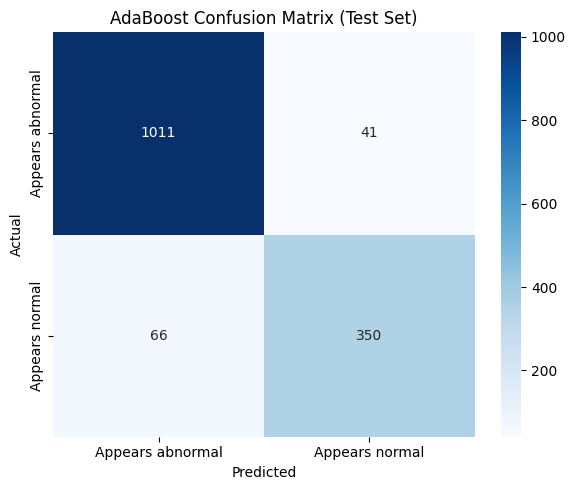


Final EfficientNet-B3 Test Loss: 0.5755 (CE: 0.6292, Dice: 0.5218), Final EfficientNet-B3 Test Accuracy: 0.8760

EfficientNet-B3 Test Precision (weighted): 0.8790
EfficientNet-B3 Test Recall (weighted): 0.8760
EfficientNet-B3 Test F1-score (weighted): 0.8685

EfficientNet-B3 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.8693    0.9734    0.9184      1052
  Appears normal     0.9034    0.6298    0.7422       416

        accuracy                         0.8760      1468
       macro avg     0.8864    0.8016    0.8303      1468
    weighted avg     0.8790    0.8760    0.8685      1468



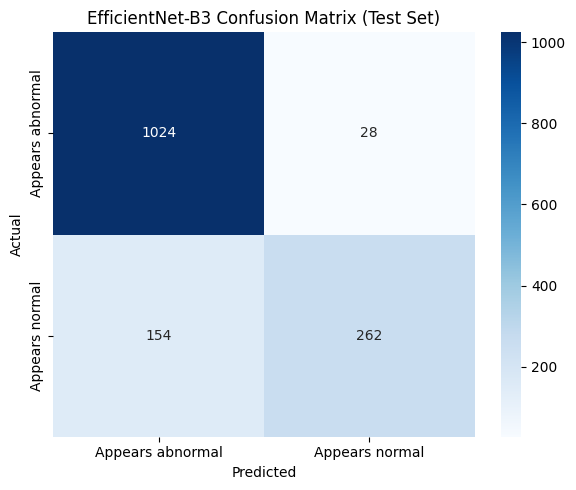

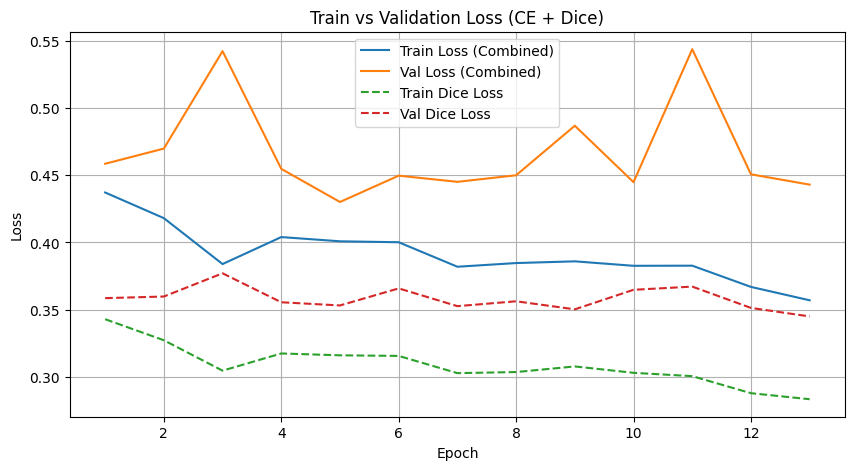

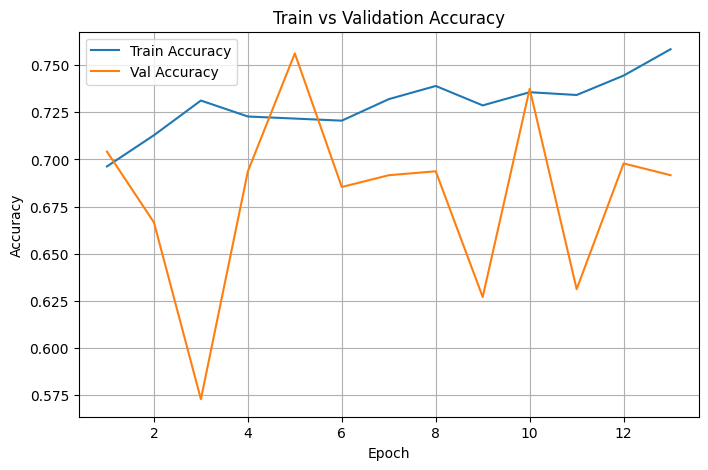


================ FINAL SUMMARY ================
Best EfficientNet-B3 Val Accuracy: 0.7562
EfficientNet-B3 Test Accuracy: 0.8760
EfficientNet-B3 Test Precision: 0.8790
EfficientNet-B3 Test Recall: 0.8760
EfficientNet-B3 Test F1-score: 0.8685
EfficientNet-B3 Test Dice Loss: 0.5218

---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.6917
AdaBoost Test Accuracy: 0.9271
AdaBoost Test Precision: 0.9264
AdaBoost Test Recall: 0.9271
AdaBoost Test F1-score: 0.9264

Run finished with fixed SEED = 512


In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import random
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.ensemble import AdaBoostClassifier

import seaborn as sns



# ============================================================
# Fixed seed run (seed = 512): single reproducible run
# ============================================================
seed = 512
print(f"\n########## SEED = {seed} ##########\n")

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ============================================================
# Device configuration
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Paths to train and test datasets
# ============================================================

train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# ============================================================
# Image transformations
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# Datasets
# ============================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)


# ============================================================
# Split train_dataset into train_subset + val_subset (85/15)
# ============================================================

val_size = int(0.15 * len(train_dataset))

train_size = len(train_dataset) - val_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)


# ============================================================
# Count samples per class within train_subset
# ============================================================

train_targets = [
    train_dataset.targets[i]
    for i in train_subset.indices
]

class_counts = np.bincount(
    train_targets
)

class_weights = 1. / class_counts

sample_weights = [
    class_weights[label]
    for label in train_targets
]


# ============================================================
# Weighted Random Sampler
# ============================================================

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)


# ============================================================
# DataLoaders
# ============================================================

train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


# ============================================================
# Load pre-trained EfficientNet-B3
# ============================================================

efficientnet = models.efficientnet_b3(
    pretrained=True
)

num_classes = len(
    train_dataset.classes
)

efficientnet.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    num_classes
)

efficientnet = efficientnet.to(device)


# ============================================================
# Dice Loss
# ============================================================

class DiceLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        smooth=1e-6
    ):

        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth


    def forward(
        self,
        logits,
        targets
    ):

        probs = F.softmax(
            logits,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            +
            targets_one_hot.sum(dim=0)
        )

        dice_score = (
            2. * intersection
            +
            self.smooth
        ) / (
            union
            +
            self.smooth
        )

        dice_loss = (
            1.
            -
            dice_score.mean()
        )

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):

        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(
            num_classes
        )

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight


    def forward(
        self,
        logits,
        targets
    ):

        ce = self.ce_loss(
            logits,
            targets
        )

        dice = self.dice_loss(
            logits,
            targets
        )

        total = (
            self.ce_weight * ce
            +
            self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


# ============================================================
# Optimizer
# ============================================================

optimizer = optim.Adam(
    efficientnet.parameters(),
    lr=0.001
)


# ============================================================
# Function to evaluate EfficientNet-B3
# ============================================================

def evaluate_model(
    model,
    loader
):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================

def get_predictions(
    model,
    loader
):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(
                outputs,
                1
            )

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================

best_accuracy = 0.0

best_model_path = "EfficientNetB3_best.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


# ============================================================
# Lists for graphs
# ============================================================

train_losses = []
train_accs = []

val_losses = []
val_accs = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# EfficientNet-B3 Training
# ============================================================

for epoch in range(max_epochs):

    efficientnet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0


    for images, labels in tqdm(
        train_loader
    ):

        images = images.to(device)
        labels = labels.to(device)

        outputs = efficientnet(
            images
        )

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(
            outputs,
            1
        )

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()


    train_accuracy = (
        correct_train /
        total_train
    )

    n_batches = len(
        train_loader
    )

    train_loss = (
        running_loss /
        n_batches
    )

    train_ce = (
        running_ce /
        n_batches
    )

    train_dice = (
        running_dice /
        n_batches
    )


    # ========================================================
    # Validation
    # ========================================================

    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        efficientnet,
        val_loader
    )


    # ========================================================
    # Store values for graphs
    # ========================================================

    train_losses.append(
        train_loss
    )

    train_accs.append(
        train_accuracy
    )

    val_losses.append(
        val_loss
    )

    val_accs.append(
        val_accuracy
    )

    train_ce_losses.append(
        train_ce
    )

    train_dice_losses.append(
        train_dice
    )

    val_ce_losses.append(
        val_ce
    )

    val_dice_losses.append(
        val_dice
    )


    # ========================================================
    # Print epoch results
    # ========================================================

    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, '
        f'Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, '
        f'Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )


    # ========================================================
    # Early stopping logic
    # ========================================================

    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: '
            f'{best_accuracy:.4f})'
        )

        torch.save(
            efficientnet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )


    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at '
            f'epoch {epoch+1}. '
            f'Best Val Accuracy: '
            f'{best_accuracy:.4f}'
        )

        break


# ============================================================
# Load the best EfficientNet-B3 model
# ============================================================

best_efficientnet_model = models.efficientnet_b3(
    pretrained=False
)

best_efficientnet_model.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    num_classes
)

best_efficientnet_model = best_efficientnet_model.to(
    device
)

best_efficientnet_model.load_state_dict(
    torch.load(
        best_model_path
    )
)


# ============================================================
# ADABOOST
# EfficientNet-B3 Feature Extraction + AdaBoost
# ============================================================

def extract_features(
    model,
    loader
):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(
            loader,
            desc="Extracting Features"
        ):

            images = images.to(device)

            # Extract features before classifier
            x = model.features(
                images
            )

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(
                x,
                (1, 1)
            )

            # Flatten
            x = torch.flatten(
                x,
                1
            )

            features.extend(
                x.cpu().numpy()
            )

            labels_list.extend(
                labels.numpy()
            )

    return (
        np.array(features),
        np.array(labels_list)
    )


print(
    "\nExtracting EfficientNet-B3 features..."
)


# ============================================================
# Feature Extraction
# ============================================================

train_features, train_labels = extract_features(
    best_efficientnet_model,
    train_loader
)

val_features, val_labels = extract_features(
    best_efficientnet_model,
    val_loader
)

test_features, test_labels = extract_features(
    best_efficientnet_model,
    test_loader
)


print(
    "\nFeature shape:",
    train_features.shape
)


# ============================================================
# Train AdaBoost
# ============================================================

adaboost_model = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=1.0,
    random_state=seed
)

print(
    "\nTraining AdaBoost..."
)

adaboost_model.fit(
    train_features,
    train_labels
)


# ============================================================
# AdaBoost Validation
# ============================================================

adaboost_val_preds = adaboost_model.predict(
    val_features
)

adaboost_val_accuracy = np.mean(
    adaboost_val_preds == val_labels
)

print(
    f"\nAdaBoost Validation Accuracy: "
    f"{adaboost_val_accuracy:.4f}"
)


# ============================================================
# AdaBoost Test Predictions
# ============================================================

adaboost_test_preds = adaboost_model.predict(
    test_features
)

adaboost_test_accuracy = np.mean(
    adaboost_test_preds == test_labels
)

print(
    f"AdaBoost Test Accuracy: "
    f"{adaboost_test_accuracy:.4f}"
)


# ============================================================
# AdaBoost Metrics
# ============================================================

class_names = train_dataset.classes


# Accuracy
adaboost_accuracy = np.mean(
    adaboost_test_preds == test_labels
)


# Weighted Precision
adaboost_precision = precision_score(
    test_labels,
    adaboost_test_preds,
    average='weighted',
    zero_division=0
)


# Weighted Recall
adaboost_recall = recall_score(
    test_labels,
    adaboost_test_preds,
    average='weighted',
    zero_division=0
)


# Weighted F1
adaboost_f1 = f1_score(
    test_labels,
    adaboost_test_preds,
    average='weighted',
    zero_division=0
)


print(
    "\n---------------- AdaBoost Metrics ----------------"
)

print(
    f"AdaBoost Test Accuracy: "
    f"{adaboost_accuracy:.4f}"
)

print(
    f"AdaBoost Test Precision (weighted): "
    f"{adaboost_precision:.4f}"
)

print(
    f"AdaBoost Test Recall (weighted): "
    f"{adaboost_recall:.4f}"
)

print(
    f"AdaBoost Test F1-score (weighted): "
    f"{adaboost_f1:.4f}"
)


# ============================================================
# AdaBoost Classification Report
# ============================================================

print(
    "\nAdaBoost Per-class report:"
)

print(
    classification_report(
        test_labels,
        adaboost_test_preds,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# AdaBoost Confusion Matrix
# ============================================================

adaboost_cm = confusion_matrix(
    test_labels,
    adaboost_test_preds
)

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    adaboost_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel(
    'Predicted'
)

plt.ylabel(
    'Actual'
)

plt.title(
    'AdaBoost Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# ORIGINAL EFFICIENTNET-B3 TEST EVALUATION
# ============================================================
# Kept from your original version
# ============================================================

test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_efficientnet_model,
    test_loader
)

print(
    f'\nFinal EfficientNet-B3 Test Loss: '
    f'{test_loss:.4f} '
    f'(CE: {test_ce:.4f}, '
    f'Dice: {test_dice:.4f}), '
    f'Final EfficientNet-B3 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# EfficientNet-B3 Test Metrics
# ============================================================

true_labels, pred_labels = get_predictions(
    best_efficientnet_model,
    test_loader
)


precision = precision_score(
    true_labels,
    pred_labels,
    average='weighted',
    zero_division=0
)

recall = recall_score(
    true_labels,
    pred_labels,
    average='weighted',
    zero_division=0
)

f1 = f1_score(
    true_labels,
    pred_labels,
    average='weighted',
    zero_division=0
)


print(
    f'\nEfficientNet-B3 Test Precision (weighted): '
    f'{precision:.4f}'
)

print(
    f'EfficientNet-B3 Test Recall (weighted): '
    f'{recall:.4f}'
)

print(
    f'EfficientNet-B3 Test F1-score (weighted): '
    f'{f1:.4f}'
)


# ============================================================
# EfficientNet-B3 Classification Report
# ============================================================

print(
    '\nEfficientNet-B3 Per-class report:'
)

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# EfficientNet-B3 Confusion Matrix
# ============================================================

cm = confusion_matrix(
    true_labels,
    pred_labels
)

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel(
    'Predicted'
)

plt.ylabel(
    'Actual'
)

plt.title(
    'EfficientNet-B3 Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel(
    'Epoch'
)

plt.ylabel(
    'Loss'
)

plt.title(
    'Train vs Validation Loss (CE + Dice)'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accs,
    label='Val Accuracy'
)

plt.xlabel(
    'Epoch'
)

plt.ylabel(
    'Accuracy'
)

plt.title(
    'Train vs Validation Accuracy'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print(
    '\n================ FINAL SUMMARY ================'
)

print(
    f'Best EfficientNet-B3 Val Accuracy: '
    f'{best_accuracy:.4f}'
)

print(
    f'EfficientNet-B3 Test Accuracy: '
    f'{test_accuracy:.4f}'
)

print(
    f'EfficientNet-B3 Test Precision: '
    f'{precision:.4f}'
)

print(
    f'EfficientNet-B3 Test Recall: '
    f'{recall:.4f}'
)

print(
    f'EfficientNet-B3 Test F1-score: '
    f'{f1:.4f}'
)

print(
    f'EfficientNet-B3 Test Dice Loss: '
    f'{test_dice:.4f}'
)


print(
    '\n---------------- AdaBoost ----------------'
)

print(
    f'AdaBoost Validation Accuracy: '
    f'{adaboost_val_accuracy:.4f}'
)

print(
    f'AdaBoost Test Accuracy: '
    f'{adaboost_accuracy:.4f}'
)

print(
    f'AdaBoost Test Precision: '
    f'{adaboost_precision:.4f}'
)

print(
    f'AdaBoost Test Recall: '
    f'{adaboost_recall:.4f}'
)

print(
    f'AdaBoost Test F1-score: '
    f'{adaboost_f1:.4f}'
)



print("\n========================================")
print(f"Run finished with fixed SEED = {seed}")
print("========================================")

# Savingg

In [7]:
# ============================================================
# ZIP PACKAGING CODE — EfficientNet-B3 + AdaBoost (Seed 512)
# Run this as the FINAL CELL after your training/evaluation code.
# It uses variables already created by your training notebook.
# ============================================================

import os
import json
import csv
import shutil
import zipfile
import platform
from pathlib import Path
from datetime import datetime, timezone

import torch
import torchvision
import numpy as np
import sklearn
import joblib

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 512
OUTPUT_DIR = "/kaggle/working"
PACKAGE_NAME = f"PCOS_EfficientNetB3_AdaBoost_Seed_{SEED}"
PACKAGE_DIR = os.path.join(OUTPUT_DIR, PACKAGE_NAME)
ZIP_PATH = os.path.join(OUTPUT_DIR, PACKAGE_NAME + ".zip")

# Confirm this is the intended training run.
if "seed" not in globals() or int(seed) != SEED:
    raise ValueError(
        f"This packaging cell is for seed {SEED}, but the notebook's "
        f"'seed' variable is {globals().get('seed', 'not found')}. "
        "Run the intended seed-512 training first."
    )

required_variables = [
    "best_efficientnet_model", "adaboost_model", "num_classes",
    "train_dataset", "train_subset", "val_subset",
    "best_accuracy", "test_accuracy", "precision", "recall", "f1",
    "test_loss", "test_ce", "test_dice",
    "adaboost_val_accuracy", "adaboost_accuracy",
    "adaboost_precision", "adaboost_recall", "adaboost_f1",
    "train_losses", "train_accs", "val_losses", "val_accs",
    "train_ce_losses", "train_dice_losses",
    "val_ce_losses", "val_dice_losses",
]
missing = [name for name in required_variables if name not in globals()]
if missing:
    raise NameError(
        "Run the training/evaluation cells first. Missing variables: "
        + ", ".join(missing)
    )

# ------------------------------------------------------------
# 2. CREATE PACKAGE DIRECTORIES
# ------------------------------------------------------------

if os.path.exists(PACKAGE_DIR):
    shutil.rmtree(PACKAGE_DIR)

for folder in ["models", "splits", "results", "config", "metadata"]:
    os.makedirs(os.path.join(PACKAGE_DIR, folder), exist_ok=True)

# ------------------------------------------------------------
# 3. SAVE BEST EFFICIENTNET-B3 MODEL
# ------------------------------------------------------------

efficientnet_path = os.path.join(
    PACKAGE_DIR, "models", "efficientnet_b3_best_seed512.pth"
)

torch.save(
    {
        "state_dict": best_efficientnet_model.state_dict(),
        "num_classes": int(num_classes),
        "classes": list(train_dataset.classes),
        "class_to_idx": train_dataset.class_to_idx,
        "seed": SEED,
        "best_val_accuracy": float(best_accuracy),
        "test_accuracy": float(test_accuracy),
        "input_size": [224, 224],
        "normalize_mean": [0.485, 0.456, 0.406],
        "normalize_std": [0.229, 0.224, 0.225],
    },
    efficientnet_path
)

# ------------------------------------------------------------
# 4. SAVE TRAINED ADABOOST CLASSIFIER
# ------------------------------------------------------------

adaboost_path = os.path.join(
    PACKAGE_DIR, "models", "adaboost_efficientnet_b3_seed512.joblib"
)
joblib.dump(adaboost_model, adaboost_path)

# ------------------------------------------------------------
# 5. SAVE TRAIN/VALIDATION SPLIT INDICES AND IMAGE MANIFEST
# ------------------------------------------------------------

split_json_path = os.path.join(
    PACKAGE_DIR, "splits", "split_indices.json"
)
split_csv_path = os.path.join(
    PACKAGE_DIR, "splits", "split_images.csv"
)

split_info = {
    "seed": SEED,
    "method": "random_split",
    "validation_fraction": 0.15,
    "train_indices": [int(i) for i in train_subset.indices],
    "val_indices": [int(i) for i in val_subset.indices],
    "classes": list(train_dataset.classes),
    "class_to_idx": train_dataset.class_to_idx,
    "note": (
        "Indices refer to train_dataset in the original notebook. "
        "They reproduce the split only when the dataset file ordering "
        "and dataset contents remain unchanged."
    ),
}

with open(split_json_path, "w", encoding="utf-8") as f:
    json.dump(split_info, f, indent=4)

# ImageFolder stores samples as (path, class_index).
with open(split_csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["split", "dataset_index", "image_name", "image_path", "class_name"])

    for split_name, indices in [
        ("train", train_subset.indices),
        ("val", val_subset.indices),
    ]:
        for index in indices:
            image_path, class_index = train_dataset.samples[int(index)]
            writer.writerow([
                split_name,
                int(index),
                os.path.basename(image_path),
                image_path,
                train_dataset.classes[int(class_index)],
            ])

# ------------------------------------------------------------
# 6. SAVE MODEL/TRAINING CONFIGURATION
# ------------------------------------------------------------

config = {
    "project": "PCOS ultrasound image classification",
    "architecture": "EfficientNet-B3 + AdaBoost",
    "seed": SEED,
    "dataset": {
        "train_directory": globals().get("train_dir"),
        "test_directory": globals().get("test_dir"),
        "classes": list(train_dataset.classes),
        "class_to_idx": train_dataset.class_to_idx,
        "split_method": "random_split",
        "validation_fraction": 0.15,
        "split_indices_file": "splits/split_indices.json",
        "split_manifest_file": "splits/split_images.csv",
    },
    "efficientnet_b3": {
        "weights_file": "models/efficientnet_b3_best_seed512.pth",
        "input_size": [224, 224],
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "batch_size": 64,
        "max_epochs": 50,
        "early_stopping_patience": 8,
        "loss": "0.5 * CrossEntropyLoss + 0.5 * DiceLoss",
        "sampler": "WeightedRandomSampler",
        "normalization_mean": [0.485, 0.456, 0.406],
        "normalization_std": [0.229, 0.224, 0.225],
        "training_augmentations": [
            "Resize(224, 224)",
            "RandomHorizontalFlip",
            "RandomRotation(20)",
        ],
    },
    "adaboost": {
        "model_file": "models/adaboost_efficientnet_b3_seed512.joblib",
        "n_estimators": 100,
        "learning_rate": 1.0,
        "random_state": SEED,
        "input_features": "EfficientNet-B3 global-average-pooled features",
    },
}

with open(
    os.path.join(PACKAGE_DIR, "config", "model_config.json"),
    "w", encoding="utf-8"
) as f:
    json.dump(config, f, indent=4)

# ------------------------------------------------------------
# 7. SAVE METRICS
# ------------------------------------------------------------

metrics = {
    "seed": SEED,
    "efficientnet_b3": {
        "best_validation_accuracy": float(best_accuracy),
        "test_accuracy": float(test_accuracy),
        "test_precision_weighted": float(precision),
        "test_recall_weighted": float(recall),
        "test_f1_weighted": float(f1),
        "test_loss": float(test_loss),
        "test_cross_entropy_loss": float(test_ce),
        "test_dice_loss": float(test_dice),
    },
    "adaboost": {
        "validation_accuracy": float(adaboost_val_accuracy),
        "test_accuracy": float(adaboost_accuracy),
        "test_precision_weighted": float(adaboost_precision),
        "test_recall_weighted": float(adaboost_recall),
        "test_f1_weighted": float(adaboost_f1),
    },
}

with open(
    os.path.join(PACKAGE_DIR, "results", "metrics.json"),
    "w", encoding="utf-8"
) as f:
    json.dump(metrics, f, indent=4)

# ------------------------------------------------------------
# 8. SAVE TRAINING HISTORY
# ------------------------------------------------------------

history = {
    "train_loss": [float(x) for x in train_losses],
    "train_accuracy": [float(x) for x in train_accs],
    "validation_loss": [float(x) for x in val_losses],
    "validation_accuracy": [float(x) for x in val_accs],
    "train_ce_loss": [float(x) for x in train_ce_losses],
    "train_dice_loss": [float(x) for x in train_dice_losses],
    "validation_ce_loss": [float(x) for x in val_ce_losses],
    "validation_dice_loss": [float(x) for x in val_dice_losses],
}

with open(
    os.path.join(PACKAGE_DIR, "results", "training_history.json"),
    "w", encoding="utf-8"
) as f:
    json.dump(history, f, indent=4)

# ------------------------------------------------------------
# 9. SAVE ENVIRONMENT INFORMATION
# ------------------------------------------------------------

environment = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "pytorch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
}

with open(
    os.path.join(PACKAGE_DIR, "metadata", "environment.json"),
    "w", encoding="utf-8"
) as f:
    json.dump(environment, f, indent=4)

# ------------------------------------------------------------
# 10. SAVE README
# ------------------------------------------------------------

readme = f"""
PCOS EfficientNet-B3 + AdaBoost — Seed {SEED}
=============================================

CONTENTS
--------
models/efficientnet_b3_best_seed512.pth
    Best EfficientNet-B3 model state and associated configuration.

models/adaboost_efficientnet_b3_seed512.joblib
    Trained AdaBoost classifier.

splits/split_indices.json
    Train/validation indices and class mapping.

splits/split_images.csv
    Image paths, names, classes, and split membership.

config/model_config.json
    Model and training configuration.

results/metrics.json
    Recorded validation and test metrics.

results/training_history.json
    Training/validation loss and accuracy history.

metadata/environment.json
    Python, library, and hardware information.

IMPORTANT
---------
1. The dataset and complete training notebook are not included.
2. Dataset paths refer to the original Kaggle environment.
3. Split indices require the same dataset contents and file ordering.
4. A seed alone does not guarantee identical results across hardware
   or software environments.
5. The metrics describe this run; they do not independently establish
   clinical validity or generalization.
"""

with open(
    os.path.join(PACKAGE_DIR, "README.txt"),
    "w", encoding="utf-8"
) as f:
    f.write(readme.strip() + "\n")

# ------------------------------------------------------------
# 11. CREATE AND VERIFY ZIP
# ------------------------------------------------------------

if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in sorted(Path(PACKAGE_DIR).rglob("*")):
        if path.is_file():
            archive.write(
                path,
                arcname=path.relative_to(OUTPUT_DIR).as_posix()
            )

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()
    if bad_file is not None:
        raise RuntimeError(f"ZIP verification failed: {bad_file}")

    print("\nZIP CONTENTS:")
    for name in archive.namelist():
        print(" -", name)

print("\nZIP CREATED AND VERIFIED SUCCESSFULLY")
print("File:", ZIP_PATH)
print(f"Size: {os.path.getsize(ZIP_PATH) / (1024 ** 2):.2f} MB")



ZIP CONTENTS:
 - PCOS_EfficientNetB3_AdaBoost_Seed_512/README.txt
 - PCOS_EfficientNetB3_AdaBoost_Seed_512/config/model_config.json
 - PCOS_EfficientNetB3_AdaBoost_Seed_512/metadata/environment.json
 - PCOS_EfficientNetB3_AdaBoost_Seed_512/models/adaboost_efficientnet_b3_seed512.joblib
 - PCOS_EfficientNetB3_AdaBoost_Seed_512/models/efficientnet_b3_best_seed512.pth
 - PCOS_EfficientNetB3_AdaBoost_Seed_512/results/metrics.json
 - PCOS_EfficientNetB3_AdaBoost_Seed_512/results/training_history.json
 - PCOS_EfficientNetB3_AdaBoost_Seed_512/splits/split_images.csv
 - PCOS_EfficientNetB3_AdaBoost_Seed_512/splits/split_indices.json

ZIP CREATED AND VERIFIED SUCCESSFULLY
File: /kaggle/working/PCOS_EfficientNetB3_AdaBoost_Seed_512.zip
Size: 38.32 MB
